# WeLoveReviews — Sentimiento de reseñas de clientes

## 1. Objetivos
¿El sentimiento de las 500 reseñas escritas coincide con la valoración externa de **4,5/5**? Distinguimos la puntuación del negocio, las estrellas de cada cliente (`rating`) y la interpretación del texto por BERT.

Responderemos: proporciones positiva/neutral/negativa; distribución de estrellas; media estimada; diferencia con 4,5; discrepancias humanas/modelo; posibles falsos negativos; patrones; limitaciones productos/servicios; conclusiones para la account manager. **4,5 estrellas no implica 90 % de textos positivos.**

In [1]:
from pathlib import Path
import sys, hashlib, platform, importlib.metadata as metadata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'src/app.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import app
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 120)
REFERENCE = 4.5
SEED = 42
BANDS = ['Negative', 'Neutral', 'Positive']
INPUT_SHA = hashlib.sha256(app.INPUT_PATH.read_bytes()).hexdigest()
assert INPUT_SHA == '63439a1a8c48fe8cc479b0b621b151b8da2415c58522b1e6b111582eef6edf10'
print('Python:', platform.python_version(), '| Plataforma:', platform.platform())
print('SHA-256 entrada:', INPUT_SHA)
display(pd.Series({name: metadata.version(name) for name in ['pandas','numpy','matplotlib','seaborn','transformers','torch','ipykernel','nbconvert','nbformat']}, name='version'))

Python: 3.13.5 | Plataforma: macOS-27.2-arm64-arm-64bit-Mach-O
SHA-256 entrada: 63439a1a8c48fe8cc479b0b621b151b8da2415c58522b1e6b111582eef6edf10


pandas           3.1.1
numpy            2.5.4
matplotlib      3.11.2
seaborn         0.13.2
transformers    5.22.2
torch           2.15.0
ipykernel        7.4.0
nbconvert       7.17.2
nbformat        5.11.1
Name: version, dtype: str

## 2. Carga y descripción del dataset
Leemos el CSV original con contrato estricto y conservamos las cadenas tal como vienen. `review_id` permite asociar cada resultado al registro original. Las conversiones numéricas se reservan para vistas analíticas.

In [2]:
reviews = app.load_reviews()
ratings = reviews.rating.astype(int)
print('Dimensiones:', reviews.shape)
display(reviews.head())
display(pd.DataFrame({'tipo_cargado': reviews.dtypes.astype(str), 'tipo_analitico': ['entero', 'entero 1–5', 'texto']}))
assert len(reviews) == 500 and reviews.review_id.astype(int).is_unique

Dimensiones: (500, 3)


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with fl...
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to ...
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasona...
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood....
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The ...


,tipo_cargado,tipo_analitico
review_id,str,entero
rating,str,entero 1–5
review_text,str,texto


## 3. EDA
Comprobamos nulos, vacíos, duplicados completos y textos repetidos por separado. Identificadores diferentes representan reseñas diferentes aunque compartan texto; no se eliminan.

,nulos,vacios_o_espacios,valores_unicos
review_id,0,0,500
rating,0,0,5
review_text,0,0,493


Filas idénticas: 0
Repeticiones adicionales de texto: 7


,review_id,rating,review_text
50,51,4,Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes ...
112,113,4,Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes ...
176,177,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our orde...
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our orde...
291,292,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remem...
483,484,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remem...
40,41,5,Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The team cle...
107,108,5,Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The team cle...
109,110,3,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite b..."
450,451,3,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite b..."


,conteo,porcentaje
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Media de rating de esta muestra: 4.5


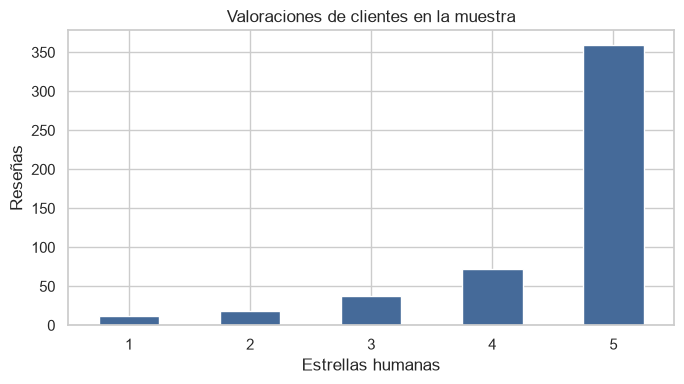

In [3]:
quality = pd.DataFrame({'nulos': reviews.isna().sum(), 'vacios_o_espacios': reviews.apply(lambda col: col.astype(str).str.strip().eq('').sum()), 'valores_unicos': reviews.nunique()})
display(quality)
print('Filas idénticas:', int(reviews.duplicated().sum()))
print('Repeticiones adicionales de texto:', int(reviews.review_text.duplicated().sum()))
display(reviews[reviews.review_text.duplicated(keep=False)].sort_values('review_text'))
human_counts = ratings.value_counts().reindex(range(1,6), fill_value=0).sort_index()
display(pd.DataFrame({'conteo': human_counts, 'porcentaje': human_counts / len(reviews) * 100}))
print('Media de rating de esta muestra:', ratings.mean())
fig, ax = plt.subplots(figsize=(7,4))
human_counts.plot.bar(ax=ax, color='#456a99', rot=0)
ax.set(title='Valoraciones de clientes en la muestra', xlabel='Estrellas humanas', ylabel='Reseñas')
plt.tight_layout(); plt.show()

Medimos caracteres y palabras antes de decidir truncamiento. Los tokens subword se medirán con el tokenizer obligatorio. Las muestras inspeccionadas están en inglés y hablan de un café; no usamos un detector de idioma adicional ni certificamos automáticamente todas las filas.

,caracteres,palabras
count,500.000000,500.000000
mean,170.170000,29.104000
std,27.058778,4.824078
min,86.000000,14.000000
25%,155.000000,26.000000
50%,173.000000,29.000000
75%,189.000000,32.000000
max,230.000000,42.000000


,review_id,rating,review_text
122,123,1,Grabbed a quick coffee at Harbor House Café this morning. The portions were way too small for the price. We waited 2...
396,397,4,Grabbed a quick coffee at Harbor House Café this morning. The sourdough bread alone is worth the visit. The staff se...
440,441,5,Grabbed a quick coffee at Harbor House Café this morning. Loved the natural light and the plants everywhere. The tea...


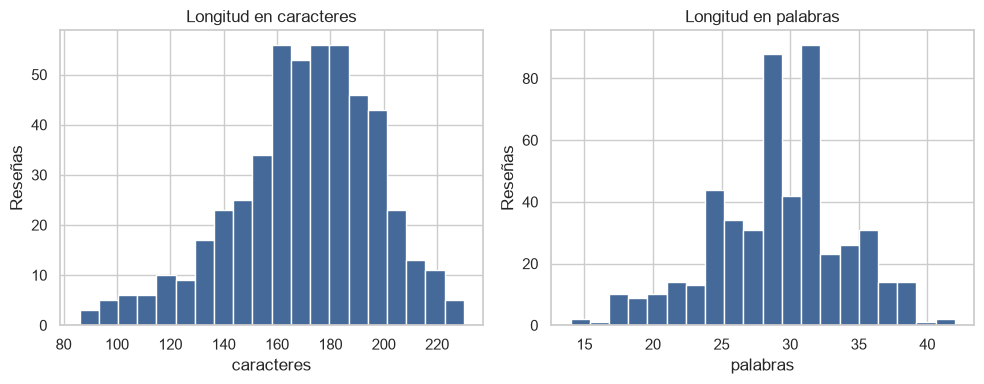

In [4]:
lengths = pd.DataFrame({'caracteres': reviews.review_text.str.len(), 'palabras': reviews.review_text.str.split().str.len()})
display(lengths.describe())
display(reviews.loc[lengths.caracteres.nlargest(3).index])
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, name in zip(axes, lengths.columns):
    ax.hist(lengths[name], bins=20, color='#456a99', edgecolor='white')
    ax.set(title=f'Longitud en {name}', xlabel=name, ylabel='Reseñas')
plt.tight_layout(); plt.show()

## 4. Insights
Las observaciones siguientes se calculan desde los datos y no anticipan las predicciones. La repetición de frases obliga a ser prudentes con la representatividad; no acredita por sí misma origen sintético.

In [5]:
display(Markdown(f"""- Hay **{len(reviews)}** reseñas y **{reviews.review_id.nunique()}** identificadores únicos.
- La muestra tiene **{int(reviews.review_text.duplicated().sum())}** repeticiones adicionales de texto, que conservamos.
- La media humana muestral es **{ratings.mean():.3f}/5**, distinta conceptualmente de la referencia externa 4,5.
- Las reseñas tienen entre **{lengths.caracteres.min()}** y **{lengths.caracteres.max()}** caracteres; falta medir tokens.
- Estos datos describen la muestra proporcionada. No conocemos período, forma de extracción ni representatividad del negocio."""))

- Hay **500** reseñas y **500** identificadores únicos.
- La muestra tiene **7** repeticiones adicionales de texto, que conservamos.
- La media humana muestral es **4.500/5**, distinta conceptualmente de la referencia externa 4,5.
- Las reseñas tienen entre **86** y **230** caracteres; falta medir tokens.
- Estos datos describen la muestra proporcionada. No conocemos período, forma de extracción ni representatividad del negocio.

## 5. Limpieza
No alteramos el contenido original: preservamos acentos, negaciones, puntuación y mayúsculas. Detectamos vacíos para elegibilidad; las filas no procesables conservarían ID y un estado explícito con predicciones vacías. No imputamos sentimiento ni borramos duplicados.

In [6]:
processable = reviews.review_text.map(lambda text: isinstance(text,str) and bool(text.strip()))
print('Procesables:', int(processable.sum()), '| No procesables:', int((~processable).sum()))
assert processable.all()
original = reviews.copy(deep=True)

Procesables: 500 | No procesables: 0


## 6. Plan de acción
1. Cargar una instancia del modelo obligatorio en CPU, con revisión exacta.
2. Medir tokens y fijar truncamiento máximo a 512 incluidos especiales.
3. Verificar conversión de etiquetas y equivalencia de lotes 8 frente a 1.
4. Inferir todas las reseñas, calcular distribuciones y comparar medias.
5. Identificar discrepancias y seleccionar 18 textos para revisión humana real.
6. Reutilizar la lógica en `src/app.py`, verificar CSV y redactar conclusiones respaldadas.

## 7. Justificación del modelo
`nlptown/bert-base-multilingual-uncased-sentiment` es BERT ajustado por sus autores en reseñas de **productos**, con cinco clases de estrellas. Soporta inglés, neerlandés, alemán, francés, italiano y español. No entrenamos ni realizamos fine-tuning.

Aplicarlo a servicios puede introducir discrepancias por esperas, personal, ambiente o experiencias mixtas. Se analizarán ejemplos reales; estas hipótesis no prueban errores. La ficha del autor no mide precisión en nuestro dataset. `score` es una puntuación de clase, no precisión calibrada.

Usamos `transformers.pipeline` con PyTorch y CPU. Modelo y tokenizer comparten SHA **8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d**. [Ficha del modelo fijada](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment/blob/8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d/README.md). Los pesos se descargan automáticamente a caché externa y no se versionan.

## 8. Integración del modelo
La función compartida crea modelo y tokenizer una sola vez. Inferencia en evaluación, sin gradientes; solo entra texto, nunca `rating`.

In [7]:
classifier = app.load_sentiment_model()
print('Modelo:', app.MODEL_NAME)
print('Revisión:', app.MODEL_REVISION)
print('Dispositivo:', classifier.device, '| Training:', classifier.model.training)
assert not classifier.model.training
assert not any(parameter.requires_grad for parameter in classifier.model.parameters())
display(pd.DataFrame({'etiqueta': list(app.LABEL_STARS), 'estrellas': list(app.LABEL_STARS.values()), 'sentimiento': [app.map_sentiment(star) for star in app.LABEL_STARS.values()]}))
assert [app.map_sentiment(i) for i in range(1,6)] == ['Negative','Negative','Neutral','Positive','Positive']

/Users/arkaitz.bregel/personales/4geeks/mrzarkas-ml-python/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1106 21:09:22.799000 10364 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 6792.81it/s]

Modelo: nlptown/bert-base-multilingual-uncased-sentiment
Revisión: 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d
Dispositivo: cpu | Training: False


,etiqueta,estrellas,sentimiento
0,1 star,1,Negative
1,2 stars,2,Negative
2,3 stars,3,Neutral
3,4 stars,4,Positive
4,5 stars,5,Positive


Truncamos solo la entrada al modelo, a 512 tokens incluidos especiales. Textos más largos podrían perder el contraste o conclusión final; registramos los IDs afectados. El CSV preserva todo el texto.

In [8]:
lengths['tokens'] = app.token_lengths(reviews, classifier)
display(lengths.tokens.describe())
truncated = reviews.loc[lengths.tokens > app.MAX_LENGTH].copy()
print('Reseñas sujetas a truncamiento:', len(truncated))
display(truncated)

count    500.000000
mean      40.656000
std        6.199559
min       20.000000
25%       37.000000
50%       41.000000
75%       44.250000
max       59.000000
Name: tokens, dtype: float64

Reseñas sujetas a truncamiento: 0


,review_id,rating,review_text


## 9. Inferencia
Comparamos un conjunto fijo de 18 entradas a lote 1 y lote 8. Si no coinciden las clases o falla lote 8, usaremos lote 1 para la ejecución completa. Las diferencias en puntuaciones flotantes no sustituyen la comprobación de clases.

In [9]:
probe = reviews.sample(n=18, random_state=SEED).sort_values('review_id').reset_index(drop=True)
single = app.predict_sentiment(probe, classifier, batch_size=1)
batched = app.predict_sentiment(probe, classifier, batch_size=8)
batch_equal = single[['predicted_stars','sentiment','processing_status']].equals(batched[['predicted_stars','sentiment','processing_status']])
BATCH_SIZE = 8 if batch_equal and batched.processing_status.eq('ok').all() else 1
print('Equivalencia de clases lote 1/8:', batch_equal, '| Lote elegido:', BATCH_SIZE)
results = app.predict_sentiment(reviews, classifier, batch_size=BATCH_SIZE)
app.validate_results(original, results)
assert hashlib.sha256(app.INPUT_PATH.read_bytes()).hexdigest() == INPUT_SHA
print('Estados:', results.processing_status.value_counts().to_dict())
assert len(results) == 500 and results.processing_status.eq('ok').all()
display(results.head())

Equivalencia de clases lote 1/8: True | Lote elegido: 8


Estados: {'ok': 500}


,review_id,rating,review_text,predicted_stars,sentiment,processing_status,processing_error
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with fl...,5,Positive,ok,
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to ...,5,Positive,ok,
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasona...,5,Positive,ok,
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood....,5,Positive,ok,
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The ...,5,Positive,ok,


## 10. Resultados
Denominador de porcentajes: reseñas con predicción válida (`N_ok`). Publicamos también cobertura total y fallos. Bandas: 1–2 Negative, 3 Neutral, 4–5 Positive.

Cobertura: 500/500; fallos: 0


,conteo,porcentaje
sentiment,,
Negative,47,9.4
Neutral,41,8.2
Positive,412,82.4


,conteo,porcentaje
predicted_stars,,
1,22,4.4
2,25,5.0
3,41,8.2
4,56,11.2
5,356,71.2


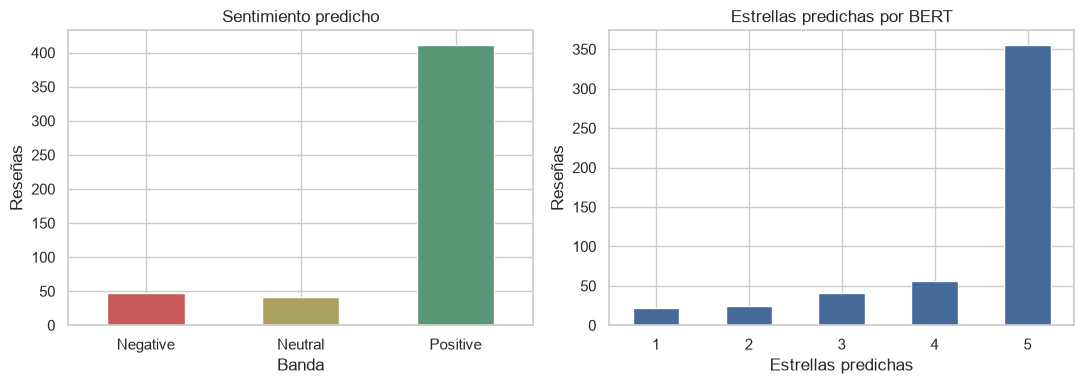

In [10]:
valid = results[results.processing_status.eq('ok')].copy()
assert len(valid) > 0
counts = valid.sentiment.value_counts().reindex(BANDS, fill_value=0)
percentages = counts / len(valid) * 100
star_counts = valid.predicted_stars.value_counts().reindex(range(1,6), fill_value=0).sort_index()
predicted_mean = float(valid.predicted_stars.mean())
print(f'Cobertura: {len(valid)}/{len(results)}; fallos: {len(results)-len(valid)}')
display(pd.DataFrame({'conteo': counts, 'porcentaje': percentages.round(2)}))
display(pd.DataFrame({'conteo': star_counts, 'porcentaje': (star_counts/len(valid)*100).round(2)}))
assert abs(percentages.sum()-100) < 1e-8
assert abs(predicted_mean - valid.predicted_stars.astype(int).sum()/len(valid)) < 1e-8
fig, axes = plt.subplots(1,2,figsize=(11,4))
counts.plot.bar(ax=axes[0], color=['#c75a5a','#aaa060','#589877'], rot=0)
axes[0].set(title='Sentimiento predicho', xlabel='Banda', ylabel='Reseñas')
star_counts.plot.bar(ax=axes[1], color='#456a99', rot=0)
axes[1].set(title='Estrellas predichas por BERT', xlabel='Estrellas predichas', ylabel='Reseñas')
plt.tight_layout(); plt.show()

## 11. Comparación con 4,5 estrellas
Comparamos tres conceptos distintos: media del modelo en los textos, media de los ratings de esta muestra y referencia externa del negocio. Las diferencias descriptivas no prueban causalidad ni representatividad.

In [11]:
human_mean = float(ratings.mean())
display(pd.Series({'media_predicha': predicted_mean, 'media_humana_muestra': human_mean, 'referencia_negocio': REFERENCE, 'diferencia_predicha_vs_negocio': predicted_mean-REFERENCE, 'diferencia_predicha_vs_humana': predicted_mean-human_mean}, name='estrellas'))
comparison = valid.copy()
comparison['rating_numeric'] = comparison.rating.astype(int)
comparison['difference'] = comparison.predicted_stars.astype(int) - comparison.rating_numeric
display(pd.crosstab(comparison.rating_numeric, comparison.predicted_stars).reindex(index=range(1,6), columns=range(1,6), fill_value=0))
print('Discrepancias exactas de estrellas:', int(comparison.difference.ne(0).sum()))
display(comparison[comparison.difference.ne(0)].sort_values('difference').head(10))

media_predicha                    4.398
media_humana_muestra              4.500
referencia_negocio                4.500
diferencia_predicha_vs_negocio   -0.102
diferencia_predicha_vs_humana    -0.102
Name: estrellas, dtype: float64

predicted_stars,1,2,3,4,5
rating_numeric,,,,,
1,3,9,0,0,0
2,7,9,2,0,0
3,0,3,35,0,0
4,1,0,3,47,21
5,11,4,1,9,335


Discrepancias exactas de estrellas: 71


,review_id,rating,review_text,predicted_stars,sentiment,processing_status,processing_error,rating_numeric,difference
86,87,5,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of th...,1,Negative,ok,,5,-4
14,15,5,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.",1,Negative,ok,,5,-4
203,204,5,Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i as...,1,Negative,ok,,5,-4
488,489,5,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly ca...,1,Negative,ok,,5,-4
473,474,5,Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Service was fast and friendly....,1,Negative,ok,,5,-4
253,254,5,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to...,1,Negative,ok,,5,-4
269,270,5,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was...,1,Negative,ok,,5,-4
321,322,5,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Wil...",1,Negative,ok,,5,-4
72,73,5,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor....,1,Negative,ok,,5,-4
408,409,5,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. Service was fast an...,1,Negative,ok,,5,-4


## 12. Posibles falsos negativos
Candidatos numéricos: predicción 1–2 con rating 4–5. Una discrepancia numérica no confirma que el texto sea positivo ni que BERT esté equivocado. La confirmación exige revisión humana textual real.

In [12]:
candidates = comparison[(comparison.predicted_stars <= 2) & (comparison.rating_numeric >= 4)].copy()
print('Candidatos numéricos:', len(candidates))
if candidates.empty:
    display(Markdown('No se encontraron candidatos con el criterio 1–2 predichas frente a 4–5 humanas. Esto no demuestra ausencia de todos los errores textuales.'))
else:
    for row in candidates.head(5).itertuples():
        display(Markdown(f'**ID {row.review_id}** — rating {row.rating}, predicción {row.predicted_stars}, banda {row.sentiment}\n\n{row.review_text}'))
phrases = ['Every dish was bursting with flavor', 'Already planning my next visit', 'accommodate my allergy']
pattern_counts = pd.DataFrame({
    'frase': phrases,
    'candidatos_con_frase': [int(candidates.review_text.str.contains(phrase, regex=False, case=False).sum()) for phrase in phrases],
    'muestra_con_frase': [int(reviews.review_text.str.contains(phrase, regex=False, case=False).sum()) for phrase in phrases]
})
display(pattern_counts)


Candidatos numéricos: 16


**ID 14** — rating 4, predicción 1, banda Negative

Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

**ID 15** — rating 5, predicción 1, banda Negative

Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.

**ID 73** — rating 5, predicción 1, banda Negative

Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.

**ID 87** — rating 5, predicción 1, banda Negative

Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!

**ID 138** — rating 5, predicción 2, banda Negative

Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit.

,frase,candidatos_con_frase,muestra_con_frase
0,Every dish was bursting with flavor,12,41
1,Already planning my next visit,11,75
2,accommodate my allergy,4,38


Los primeros ejemplos incluyen frases sobre sabor, atención y regreso al café: IDs 14, 15 y 73 comparten “Every dish was bursting with flavor”; IDs 87 y 138 mencionan acomodar una alergia. La tabla cuantifica frases repetidas dentro de los candidatos y en la muestra completa. **No todos estos ejemplos contienen quejas o experiencias mixtas**: el desajuste de dominio no explica automáticamente sus predicciones.

Son patrones léxicos observados y posibles hipótesis para investigar, no causas demostradas ni revisión humana completada. Se debe comprobar si el contexto completo expresa positividad, ambigüedad o ironía antes de confirmar cada falso negativo.

## 13. Validación manual
Seleccionamos 18 IDs únicos con semilla 42: hasta seis por banda disponible, incluyendo candidatos discrepantes cuando existan; redistribuimos cupos escasos. La muestra dirigida permite inspeccionar errores y **no estima precisión poblacional**.

La tabla de revisión se guarda en `data/interim/manual_review.csv` para que un revisor humano complete `manual_sentiment` (Negative/Neutral/Positive/Ambiguous), `reason`, `reviewer` y `reviewed_at`. No se rellenan etiquetas con IA. Se recomienda leer el texto antes de mirar rating/predicción.

In [13]:
selected = []
rng = np.random.default_rng(SEED)
ordered = comparison.assign(id_numeric=comparison.review_id.astype(int)).sort_values('id_numeric')
for band in BANDS:
    group = ordered[ordered.sentiment.eq(band)]
    if group.empty:
        continue
    discrepant = group[(group.predicted_stars <= 2) & (group.rating_numeric >= 4)]
    if not discrepant.empty:
        selected.append(int(rng.choice(discrepant.index.to_numpy())))
    remaining = group.loc[~group.index.isin(selected)]
    quota = min(6, len(group)) - len([i for i in selected if i in group.index])
    if quota:
        selected.extend(rng.choice(remaining.index.to_numpy(), size=quota, replace=False).tolist())
remaining = ordered.loc[~ordered.index.isin(selected)]
if len(selected) < 18:
    selected.extend(rng.choice(remaining.index.to_numpy(), size=18-len(selected), replace=False).tolist())
sample = comparison.loc[selected, ['review_id','review_text','rating','predicted_stars','sentiment']].copy().sort_values('review_id', key=lambda s:s.astype(int))
assert len(sample) == 18 and sample.review_id.is_unique
manual_path = ROOT / 'data/interim/manual_review.csv'
if not manual_path.exists():
    template = sample.copy()
    for name in ['manual_sentiment','reason','reviewer','reviewed_at']:
        template[name] = ''
    template.to_csv(manual_path, index=False)
annotations = pd.read_csv(manual_path, dtype=str, keep_default_na=False)
assert annotations.review_id.is_unique and set(annotations.review_id) == set(sample.review_id)
annotation_columns = ['manual_sentiment','reason','reviewer','reviewed_at']
assert all(name in annotations.columns for name in annotation_columns)
expected = sample.astype(str).set_index('review_id').sort_index()
# Admitir archivo de anotaciones por ID sin duplicar el texto/predicciones.
# Si incluye campos originales, comprobar que siguen correspondiendo a la muestra.
for name in expected.columns.intersection(annotations.columns):
    pd.testing.assert_series_equal(expected[name], annotations.set_index('review_id')[name].sort_index(), check_names=False)
manual = sample.astype(str).merge(annotations[['review_id'] + annotation_columns], on='review_id', validate='one_to_one')
allowed = ['Negative','Neutral','Positive','Ambiguous']
reviewed = manual.manual_sentiment.isin(allowed) & manual[['reason','reviewer','reviewed_at']].apply(lambda c:c.str.strip().ne('')).all(axis=1)
manual_complete = bool(reviewed.all())
print('Cuotas por banda:', sample.sentiment.value_counts().to_dict())
print(f'Revisión humana completa: {int(reviewed.sum())}/18')
display(manual)
if not manual_complete:
    display(Markdown('**Pendiente de revisión humana real.** No se declara accuracy ni errores confirmados. El archivo conserva campos de anotación vacíos hasta recibir evidencia del revisor.'))
else:
    manual['textual_error'] = manual.manual_sentiment.ne(manual.sentiment) & manual.manual_sentiment.ne('Ambiguous')
    display(manual[['review_id','manual_sentiment','textual_error','reason','reviewer','reviewed_at']])
if manual_complete:
    confirmed_fn = manual[(manual.sentiment == 'Negative') & (manual.manual_sentiment == 'Positive')]
    print('Acuerdos en muestra dirigida:', int(manual.manual_sentiment.eq(manual.sentiment).sum()), '/', len(manual))
    print('Discrepancias textuales según el revisor:', int(manual.textual_error.sum()))
    display(pd.crosstab(manual.manual_sentiment, manual.sentiment).reindex(index=allowed, columns=BANDS, fill_value=0))
    print('Falsos negativos confirmados en la muestra:', len(confirmed_fn))
    display(confirmed_fn[['review_id','review_text','rating','predicted_stars','reason','reviewer','reviewed_at']])


Cuotas por banda: {'Negative': 6, 'Positive': 6, 'Neutral': 6}
Revisión humana completa: 18/18


,review_id,review_text,rating,predicted_stars,sentiment,manual_sentiment,reason,reviewer,reviewed_at
0,15,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.",5,1,Negative,Positive,"La reseña es completamente positiva: elogia la comida y el ambiente, y expresa intención de regresar.",ark,2026-11-06
1,92,Came to Harbor House Café for a birthday brunch. The seasonal menu never disappoints. Loved the natural light and th...,5,5,Positive,Positive,"Destaca el menú, el ambiente y la relación calidad-precio, sin críticas.",ark,2026-11-06
2,185,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. The pastries w...,5,5,Positive,Positive,"Valora positivamente el trato personalizado, la comida y los precios.",ark,2026-11-06
3,195,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our orde...,2,1,Negative,Negative,"Describe comida de mala calidad, precios elevados y errores de servicio.",ark,2026-11-06
4,208,Visited Harbor House Café last weekend. The staff were warm and attentive. The seasonal menu never disappoints. Wort...,5,5,Positive,Positive,"Destaca la atención, el menú y la intención de volver habitualmente.",ark,2026-11-06
5,233,Stopped by Harbor House Café for the first time. The coffee was okay. The staff were polite but a bit slow. Might gi...,3,3,Neutral,Neutral,"Valoración mixta: café aceptable, personal educado, pero servicio lento.",ark,2026-11-06
6,254,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to...,5,1,Negative,Positive,"Elogia la atención personalizada, el espacio y la intención de regresar.",ark,2026-11-06
7,321,Tried Harbor House Café after seeing it recommended online. Fresh ingredients you can really taste. We waited 25 min...,5,5,Positive,Neutral,"Aunque hay una crítica al tiempo de espera, el cliente manifiesta satisfacción global y recomienda el local.",ark,2026-11-06
8,322,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Wil...",5,1,Negative,Neutral,"Reseña mixta con crítica al personal, pero la valoración final es positiva por la comida y la intención de volver.",ark,2026-11-06
9,359,"Tried Harbor House Café after seeing it recommended online. The food was decent, nothing special. Service was fine, ...",3,3,Neutral,Neutral,"Experiencia aceptable, sin elementos especialmente buenos o malos.",ark,2026-11-06


,review_id,manual_sentiment,textual_error,reason,reviewer,reviewed_at
0,15,Positive,True,"La reseña es completamente positiva: elogia la comida y el ambiente, y expresa intención de regresar.",ark,2026-11-06
1,92,Positive,False,"Destaca el menú, el ambiente y la relación calidad-precio, sin críticas.",ark,2026-11-06
2,185,Positive,False,"Valora positivamente el trato personalizado, la comida y los precios.",ark,2026-11-06
3,195,Negative,False,"Describe comida de mala calidad, precios elevados y errores de servicio.",ark,2026-11-06
4,208,Positive,False,"Destaca la atención, el menú y la intención de volver habitualmente.",ark,2026-11-06
5,233,Neutral,False,"Valoración mixta: café aceptable, personal educado, pero servicio lento.",ark,2026-11-06
6,254,Positive,True,"Elogia la atención personalizada, el espacio y la intención de regresar.",ark,2026-11-06
7,321,Neutral,True,"Aunque hay una crítica al tiempo de espera, el cliente manifiesta satisfacción global y recomienda el local.",ark,2026-11-06
8,322,Neutral,True,"Reseña mixta con crítica al personal, pero la valoración final es positiva por la comida y la intención de volver.",ark,2026-11-06
9,359,Neutral,False,"Experiencia aceptable, sin elementos especialmente buenos o malos.",ark,2026-11-06


Acuerdos en muestra dirigida: 13 / 18
Discrepancias textuales según el revisor: 5


sentiment,Negative,Neutral,Positive
manual_sentiment,,,
Negative,2,0,0
Neutral,1,6,1
Positive,3,0,5
Ambiguous,0,0,0


Falsos negativos confirmados en la muestra: 3


,review_id,review_text,rating,predicted_stars,reason,reviewer,reviewed_at
0,15,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.",5,1,"La reseña es completamente positiva: elogia la comida y el ambiente, y expresa intención de regresar.",ark,2026-11-06
6,254,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to...,5,1,"Elogia la atención personalizada, el espacio y la intención de regresar.",ark,2026-11-06
17,489,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly ca...,5,1,"Elogia la comida, la atención y el precio, además de expresar intención de volver.",ark,2026-11-06


## 14. Conclusiones para la account manager
Las cifras siguientes proceden de la inferencia ejecutada. Las conclusiones sobre errores textuales seguirán siendo provisionales hasta completar la revisión humana.

In [14]:
display(Markdown(f"""De las **{len(valid)}** reseñas procesadas, **{percentages['Positive']:.2f} %** expresan sentimiento positivo según el modelo, **{percentages['Neutral']:.2f} %** neutral y **{percentages['Negative']:.2f} %** negativo.

La valoración textual media estimada es **{predicted_mean:.3f}/5**, una diferencia de **{predicted_mean-REFERENCE:+.3f} estrellas** frente a 4,5. La media humana de esta muestra es **{human_mean:.3f}/5**. Estas medias son descriptivas y no equivalen al porcentaje positivo.

Encontramos **{len(candidates)}** candidatos numéricos a falsos negativos. No son errores confirmados sin revisar el texto. El modelo fue ajustado en productos y aquí analiza servicios; las experiencias mixtas, ironía y contexto requieren cuidado. **{len(truncated)}** reseñas superaron 512 tokens.

Revisión humana: **{'completa' if manual_complete else 'pendiente'}**. La muestra de 18 casos fue dirigida y no permite estimar precisión poblacional. La representatividad de las 500 reseñas respecto a la puntuación externa no está verificada."""))
if manual_complete:
    display(Markdown(f"""La revisión realizada por **{', '.join(manual.reviewer.unique())}** el **{', '.join(manual.reviewed_at.unique())}** completa los 18 casos seleccionados. Hay **{int(manual.manual_sentiment.eq(manual.sentiment).sum())}/18** coincidencias de banda y **{int(manual.textual_error.sum())}** discrepancias textuales según ese revisor. Se confirma **{len(confirmed_fn)}** falso negativo en esta muestra: IDs **{', '.join(confirmed_fn.review_id)}**.

Las anotaciones de casos mixtos conservan el criterio del revisor; las razones de los IDs 321 y 322 destacan valoración final positiva, aunque su etiqueta manual es Neutral. Esto refleja una decisión discutible sobre cómo ponderar componentes mixtos y limita interpretar el desacuerdo como fallo universal del modelo. No se corrigen las anotaciones humanas automáticamente.

La media textual predicha queda **0,102 estrellas por debajo** de 4,5 y el modelo clasifica una amplia mayoría como positiva. La coincidencia es aproximada y descriptiva: sin un umbral acordado ni validación representativa no afirmamos equivalencia estadística. Los errores observados justifican revisar ejemplos concretos antes de usar las predicciones para decisiones individuales. La validación de 18 casos dirigida no permite extrapolar una tasa de error a las 500 reseñas."""))


De las **500** reseñas procesadas, **82.40 %** expresan sentimiento positivo según el modelo, **8.20 %** neutral y **9.40 %** negativo.

La valoración textual media estimada es **4.398/5**, una diferencia de **-0.102 estrellas** frente a 4,5. La media humana de esta muestra es **4.500/5**. Estas medias son descriptivas y no equivalen al porcentaje positivo.

Encontramos **16** candidatos numéricos a falsos negativos. No son errores confirmados sin revisar el texto. El modelo fue ajustado en productos y aquí analiza servicios; las experiencias mixtas, ironía y contexto requieren cuidado. **0** reseñas superaron 512 tokens.

Revisión humana: **completa**. La muestra de 18 casos fue dirigida y no permite estimar precisión poblacional. La representatividad de las 500 reseñas respecto a la puntuación externa no está verificada.

La revisión realizada por **ark** el **2026-11-06** completa los 18 casos seleccionados. Hay **13/18** coincidencias de banda y **5** discrepancias textuales según ese revisor. Se confirma **3** falso negativo en esta muestra: IDs **15, 254, 489**.

Las anotaciones de casos mixtos conservan el criterio del revisor; las razones de los IDs 321 y 322 destacan valoración final positiva, aunque su etiqueta manual es Neutral. Esto refleja una decisión discutible sobre cómo ponderar componentes mixtos y limita interpretar el desacuerdo como fallo universal del modelo. No se corrigen las anotaciones humanas automáticamente.

La media textual predicha queda **0,102 estrellas por debajo** de 4,5 y el modelo clasifica una amplia mayoría como positiva. La coincidencia es aproximada y descriptiva: sin un umbral acordado ni validación representativa no afirmamos equivalencia estadística. Los errores observados justifican revisar ejemplos concretos antes de usar las predicciones para decisiones individuales. La validación de 18 casos dirigida no permite extrapolar una tasa de error a las 500 reseñas.

### Verificación de artefactos
El script independiente genera el CSV enriquecido. Comparamos sus predicciones con las de este notebook bajo la misma configuración, conservando texto e identificadores. No se copia la inferencia del notebook para simular ejecución del script.

In [15]:
production = pd.read_csv(app.OUTPUT_PATH, keep_default_na=False, dtype=str)
production['predicted_stars'] = pd.to_numeric(production.predicted_stars, errors='coerce').astype('Int64')
app.validate_results(original, production)
pd.testing.assert_frame_equal(results, production, check_dtype=False)
assert hashlib.sha256(app.INPUT_PATH.read_bytes()).hexdigest() == INPUT_SHA
print('CSV de producción consistente con notebook:', len(production), 'filas')
print('Dataset original intacto. Revisión humana:', 'completa' if manual_complete else 'pendiente')

CSV de producción consistente con notebook: 500 filas
Dataset original intacto. Revisión humana: completa
